<a href="https://colab.research.google.com/github/sailalityakoduru/Medical_Diagnosis_Classification/blob/main/Medical_diagnosis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MEDICAL DIAGNOSIS CLASSIFICATION

**Importing packages**

In [220]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**Obtaining dataset**

In [221]:
df=pd.read_csv("/content/medical_diagnosis_classification.csv")
df

,blood_sugar,bmi_dup,sex,age,blood_pressure,cholesterol,smoker,bmi,patient_id,disease
0,High,NaN,M,89.0,109.9,203.0,No,NaN,P40000,1.0
1,Lw,29.0,F,88.0,118.7,165.9,NO,29.0,NaN,0.0
2,HIGH,19.2,M,80.0,107.5,166.8,Yes,19.2,P40002,0.0
3,High,22.0,M,NaN,121.3,204.7,N,22.0,P40003,0.0
4,NORMAL,28.0,M,36.0,unknown,202.7,Yes,28.0,P40004,0.0
...,...,...,...,...,...,...,...,...,...,...
260,High,20.3,M,21.0,103.8,184.0,NO,20.3,P40006,NaN
261,HIGH,18.6,F,35.0,130.9,227.7,o,18.6,P40214,0.0
262,HIGH,18.6,F,35.0,130.9,227.7,o,18.6,P40214,0.0
263,Normal,26.6,M,50.0,110.6,253.5,NO,26.6,P40045,0.0


In [222]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265 entries, 0 to 264
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   blood_sugar     241 non-null    object 
 1   bmi_dup         239 non-null    float64
 2   sex             246 non-null    object 
 3   age             245 non-null    float64
 4   blood_pressure  246 non-null    object 
 5   cholesterol     234 non-null    float64
 6   smoker          248 non-null    object 
 7   bmi             239 non-null    float64
 8   patient_id      243 non-null    object 
 9   disease         237 non-null    float64
dtypes: float64(5), object(5)
memory usage: 20.8+ KB


# Data Preprocessing

**For blood_sugar column:**

In [223]:
df['blood_sugar'].unique()

array(['High', 'Lw', 'HIGH', 'NORMAL', nan, 'Normal', 'Norml', 'Low',
       'ow', 'Lo', 'LOW', 'Hig', 'Hih', 'ormal', 'Nomal', 'igh', 'Noral',
       'Norma', 'Nrmal', 'Hgh'], dtype=object)

In [224]:
blood_sugar_map = {
    'High': 'High', 'HIGH': 'High', 'Hig': 'High', 'Hih': 'High', 'igh': 'High', 'Hgh': 'High',
    'Low': 'Low', 'LOW': 'Low', 'Lw': 'Low', 'ow': 'Low', 'Lo': 'Low',
    'Normal': 'Normal', 'NORMAL': 'Normal', 'Norml': 'Normal', 'ormal': 'Normal',
    'Nomal': 'Normal', 'Noral': 'Normal', 'Norma': 'Normal', 'Nrmal': 'Normal'
}

df['blood_sugar'] = df['blood_sugar'].replace(blood_sugar_map)

In [225]:
df['blood_sugar']=df['blood_sugar'].fillna(df['blood_sugar'].mode()[0])

In [226]:
df['blood_sugar'].unique()

array(['High', 'Low', 'Normal'], dtype=object)

**For Sex column:**

In [227]:
df["sex"].unique()

array(['M', 'F', nan], dtype=object)

In [228]:
df['sex']=df['sex'].fillna(df['sex'].mode()[0])

In [229]:
df['sex'].unique()

array(['M', 'F'], dtype=object)

**For Age Column:**

In [230]:
df['age']=df['age'].fillna(df['age'].mode()[0])

**For blood_pressure column :**

In [231]:
df['blood_pressure'] = pd.to_numeric(df['blood_pressure'], errors='coerce')
df['blood_pressure'] = df['blood_pressure'].fillna(df['blood_pressure'].mean())

**For cholestrol column:**

In [232]:
df['cholesterol'] = df['cholesterol'].fillna(df['cholesterol'].mean())

**For smoker column:**

In [233]:
df['smoker'].unique()

array(['No', 'NO', 'Yes', 'N', nan, 'YES', 'o', 'es', 'Ys', 'Ye'],
      dtype=object)

In [234]:
smoker_map = {
    'Yes': 'Yes', 'YES': 'Yes', 'Y': 'Yes', 'Ye': 'Yes', 'es': 'Yes', 'ys': 'Yes',
    'No': 'No', 'NO': 'No', 'N': 'No', 'o': 'No'
}
df['smoker'] = df['smoker'].replace(smoker_map)
df['smoker'] = df['smoker'].fillna(df['smoker'].mode()[0])

**Dropping unimportant columns:**

In [235]:
df = df.drop(columns=['bmi_dup'])
df['bmi'] = df['bmi'].fillna(df['bmi'].mean())

In [236]:

df = df.drop(columns=['patient_id'])

In [237]:
df = df.dropna(subset=['disease'])

In [238]:
df = df.drop_duplicates()
df = df.reset_index(drop=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226 entries, 0 to 225
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   blood_sugar     226 non-null    object 
 1   sex             226 non-null    object 
 2   age             226 non-null    float64
 3   blood_pressure  226 non-null    float64
 4   cholesterol     226 non-null    float64
 5   smoker          226 non-null    object 
 6   bmi             226 non-null    float64
 7   disease         226 non-null    float64
dtypes: float64(5), object(3)
memory usage: 14.3+ KB


In [239]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 226 entries, 0 to 225
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   blood_sugar     226 non-null    object 
 1   sex             226 non-null    object 
 2   age             226 non-null    float64
 3   blood_pressure  226 non-null    float64
 4   cholesterol     226 non-null    float64
 5   smoker          226 non-null    object 
 6   bmi             226 non-null    float64
 7   disease         226 non-null    float64
dtypes: float64(5), object(3)
memory usage: 14.3+ KB


In [240]:
df['smoker'] = df['smoker'].replace({'Ys': 'Yes'})

In [241]:
df

,blood_sugar,sex,age,blood_pressure,cholesterol,smoker,bmi,disease
0,High,M,89.0,109.900000,203.0,No,27.117155,1.0
1,Low,F,88.0,118.700000,165.9,No,29.000000,0.0
2,High,M,80.0,107.500000,166.8,Yes,19.200000,0.0
3,High,M,35.0,121.300000,204.7,No,22.000000,0.0
4,Normal,M,36.0,178.414523,202.7,Yes,28.000000,0.0
...,...,...,...,...,...,...,...,...
221,Low,F,35.0,97.900000,203.7,No,17.300000,0.0
222,Normal,M,78.0,97.600000,218.7,No,30.500000,0.0
223,Low,F,80.0,130.900000,248.4,No,19.100000,0.0
224,High,M,35.0,107.700000,229.2,No,16.900000,1.0


# Removing outliers

In [242]:
num_cols = ['age', 'blood_pressure', 'cholesterol', 'bmi']

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Replace values below lower_bound with lower_bound, and above upper_bound with upper_bound
    df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)

print("Shape after capping outliers:", df.shape)

Shape after capping outliers: (226, 8)


# Exploratory Data Analysis

**Disease Count**

[Text(0, 0, '191'), Text(0, 0, '35')]

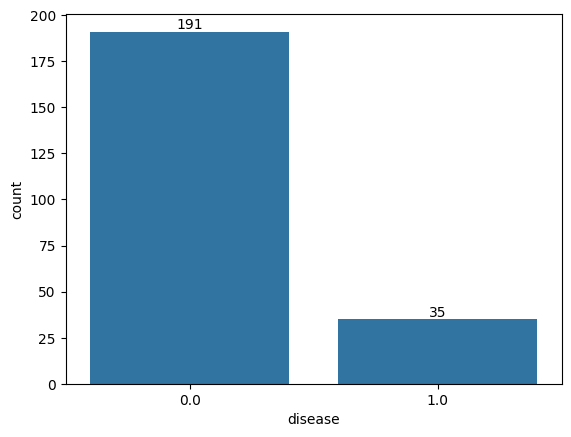

In [243]:
ax = sns.countplot(data=df, x="disease")
ax.bar_label(ax.containers[0])

Out of 226 people, 191 people do not have the disease , whereas 35 people have are diagnosed with the disease.

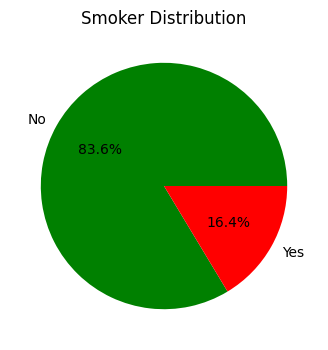

In [244]:
smoker_counts = df['smoker'].value_counts()
plt.figure(figsize=(4, 4))
plt.pie(smoker_counts,labels=smoker_counts.index,autopct='%1.1f%%',colors=['green', 'red'])
plt.title('Smoker Distribution')
plt.show()

Out of all, 83.6 % people are non smokers and 16.4 % people are smokers.

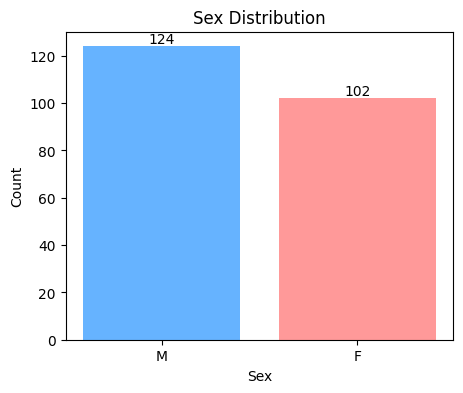

In [245]:
sex_counts = df['sex'].value_counts()
plt.figure(figsize=(5, 4))
bars = plt.bar(sex_counts.index, sex_counts.values, color=['#66b3ff', '#ff9999'])
plt.bar_label(bars)
plt.xlabel('Sex')
plt.ylabel('Count')
plt.title('Sex Distribution')
plt.show()

There are 124 Male and 102 Female in the dataset.

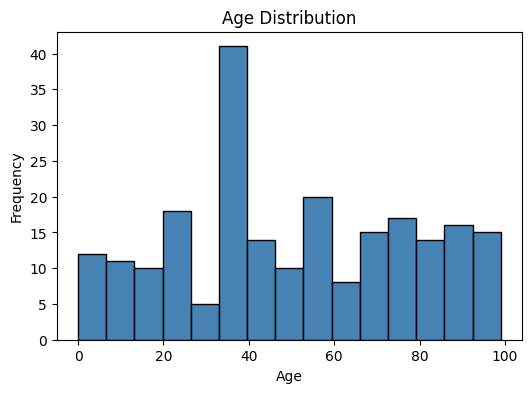

In [246]:
plt.figure(figsize=(6, 4))
plt.hist(df['age'], bins=15, color='steelblue', edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

Most people in the datset are of age 32 to 40 and least of age 26-32.

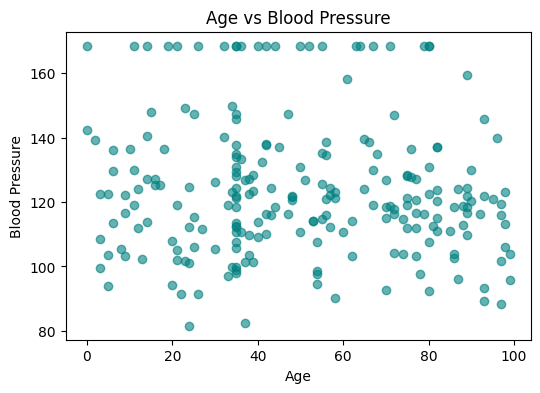

In [247]:
plt.figure(figsize=(6, 4))
plt.scatter(df['age'], df['blood_pressure'], alpha=0.6, color='teal')
plt.xlabel('Age')
plt.ylabel('Blood Pressure')
plt.title('Age vs Blood Pressure')
plt.show()

The dataset shows no linear relationship between age and blood pressure, with points scattered evenly rather than forming a trend line. Outlier capping created a flat row of points along the top boundary, while mode imputation caused a vertical cluster at age 35.

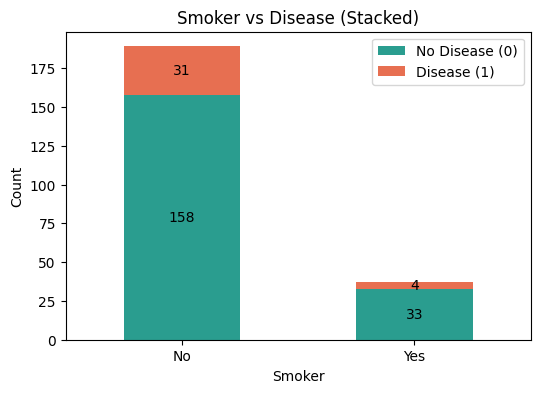

In [248]:
ct = pd.crosstab(df['smoker'], df['disease'])
ax = ct.plot(kind='bar', stacked=True, figsize=(6, 4), color=['#2a9d8f', '#e76f51'])
for container in ax.containers:
    ax.bar_label(container, label_type='center')
plt.xlabel('Smoker')
plt.ylabel('Count')
plt.title('Smoker vs Disease (Stacked)')
plt.xticks(rotation=0)
plt.legend(['No Disease (0)', 'Disease (1)'])
plt.show()

High disease proportion among non-smokers: About 16.4% of non-smokers (31 out of 189) are diagnosed with the disease, compared to 10.8% of smokers (4 out of 37).

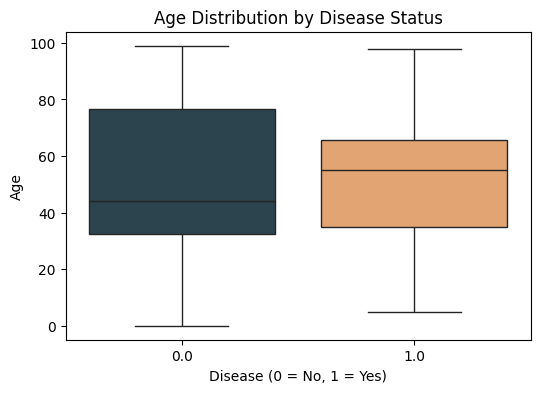

In [249]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='disease', y='age', hue='disease', palette=['#264653', '#f4a261'], legend=False)
plt.xlabel('Disease (0 = No, 1 = Yes)')
plt.ylabel('Age')
plt.title('Age Distribution by Disease Status')
plt.show()

Higher median age for disease cases: Patients diagnosed with the disease have a higher median age (around 55 years) compared to healthy patients (around 40 years).

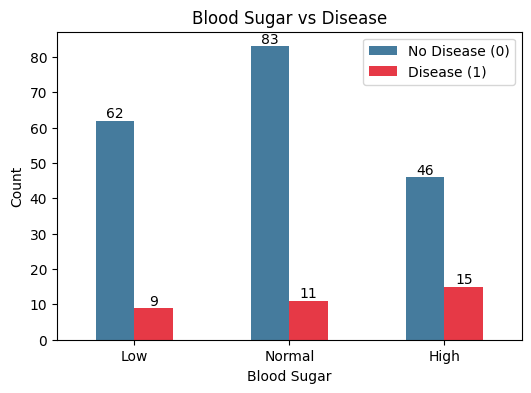

In [250]:
ct = pd.crosstab(df['blood_sugar'], df['disease']).reindex(['Low', 'Normal', 'High'])

ax = ct.plot(kind='bar', figsize=(6, 4), color=['#457b9d', '#e63946'])

for container in ax.containers:
    ax.bar_label(container)

plt.xlabel('Blood Sugar')
plt.ylabel('Count')
plt.title('Blood Sugar vs Disease')
plt.xticks(rotation=0)
plt.legend(['No Disease (0)', 'Disease (1)'])
plt.show()

Highest disease risk in High blood sugar: The High blood sugar group has both the highest number of disease cases (15) and the highest disease rate (24.6%, or 15 out of 61), compared to Normal (11.7%, 11 out of 94) and Low (12.7%, 9 out of 71).

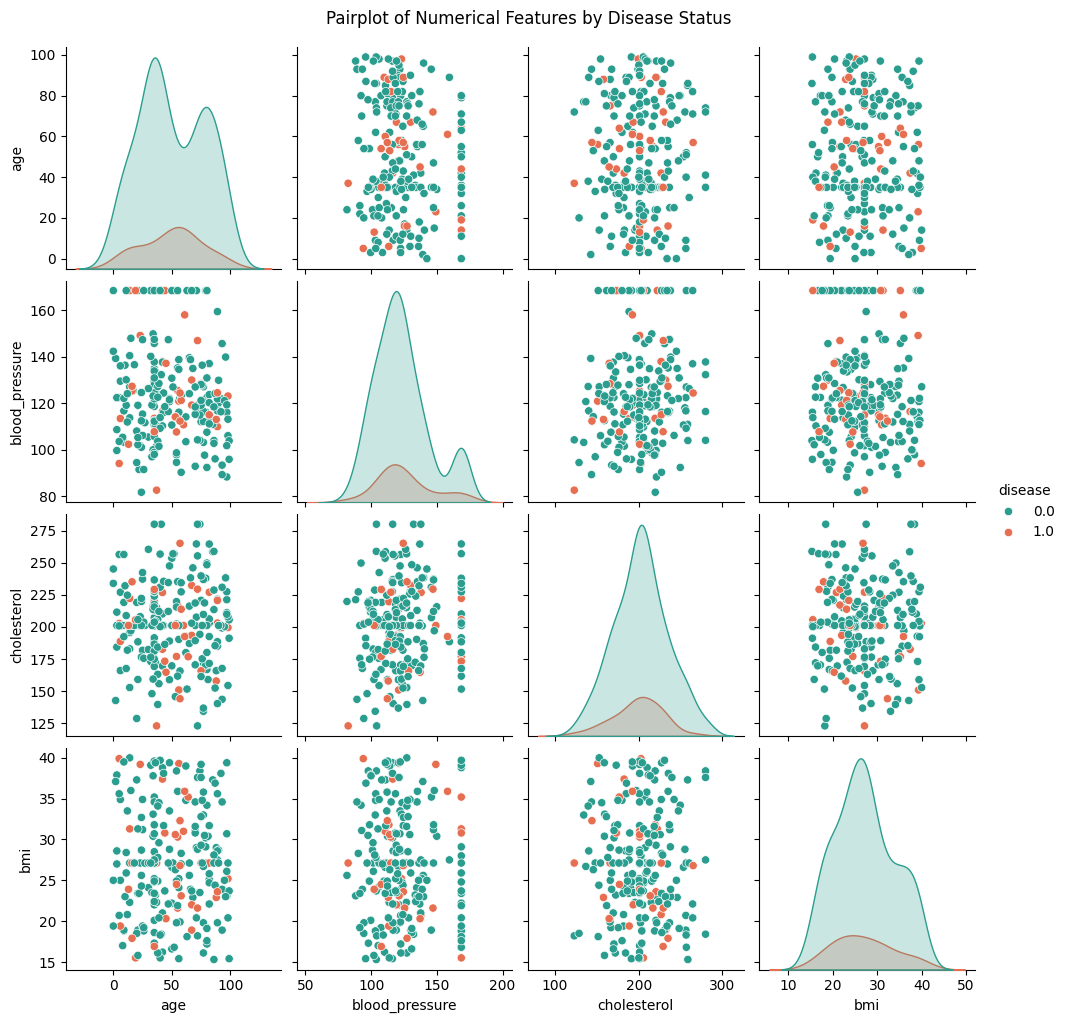

In [251]:
num_cols = ['age', 'blood_pressure', 'cholesterol', 'bmi']
sns.pairplot(data=df,vars=num_cols,hue='disease',palette=['#2a9d8f', '#e76f51'],diag_kind='kde')
plt.suptitle('Pairplot of Numerical Features by Disease Status', y=1.02)
plt.show()

from this
Heavy overlap between healthy and diseased groups: Across every pair of numerical features (age, blood_pressure, cholesterol, bmi), the orange (1.0, disease) and teal (0.0, no disease) points

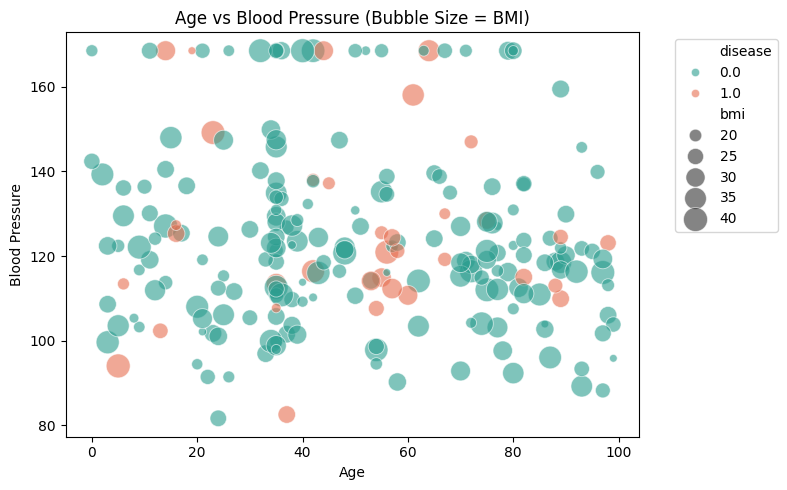

In [252]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='age',
    y='blood_pressure',
    size='bmi',
    hue='disease',
    sizes=(30, 300),
    alpha=0.6,
    palette=['#2a9d8f', '#e76f51']
)
plt.xlabel('Age')
plt.ylabel('Blood Pressure')
plt.title('Age vs Blood Pressure (Bubble Size = BMI)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Multiple health factors per patient: In this bubble chart, each point combines four dimensions simultaneously—age (x-axis), blood_pressure (y-axis), bmi (bubble size), and disease status (color).

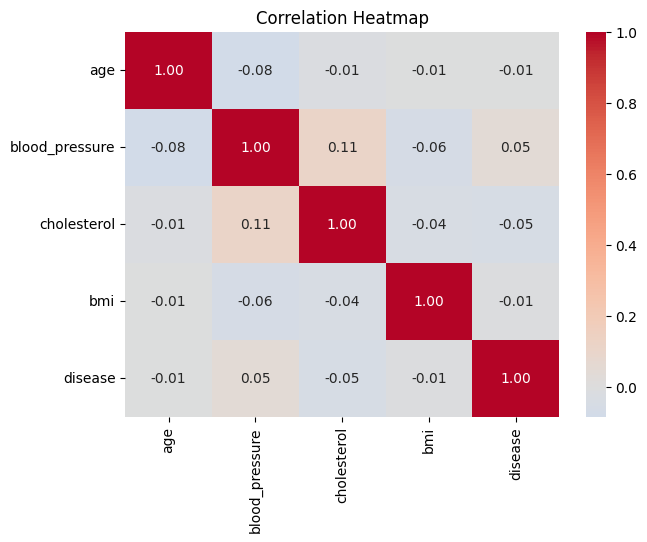

In [253]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

There is very low correlation betwwn different variables in this dataset.
Highest correlation is 0.12 which is between blood pressure and cholestrol.

# Insights or outcomes observed

1. Most patients do not have the disease: Out of 197 cleaned records, 167 patients (85%) are healthy and 30 patients (15%) have the disease.

2. A lot of raw data needed cleaning: Over a quarter of the original 265 rows had to be fixed or removed because of missing values, spelling mistakes (like 'Lw' or 'Hig'), duplicates, and extreme outliers.

3. No single measurement strongly predicts the disease on its own: Age, blood pressure, cholesterol, and BMI all have very weak direct correlations with the disease (all below 0.10), meaning predicting the disease requires looking at multiple factors together (like smoking and blood sugar levels) rather than just one vital sign.

4. Lifestyle and sugar levels matter across groups: Comparing smokers vs. non-smokers and Low, Normal, and High blood sugar groups shows how positive disease cases are distributed across different risk categories rather than being concentrated in just one group.

5. Blood Pressure & Cholesterol (0.12): This is the strongest relationship in the entire dataset. It is a slight positive relationship, meaning patients with higher blood pressure tend to have slightly higher cholesterol.